# Analisis Regresi Konsumsi Energi Terbarukan di Amerika Serikat: Data Understanding, Cleaning, Preprocessing, dan Feature Selection


In [1]:
import warnings; warnings.filterwarnings("ignore")
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats
from statsmodels.tsa.seasonal import STL
from statsmodels.tsa.stattools import adfuller, acf
from statsmodels.graphics.tsaplots import plot_acf

DATA = Path("data/dataset.csv")
FIG, OUT = Path("figures"), Path("outputs")
FIG.mkdir(exist_ok=True); OUT.mkdir(exist_ok=True)

plt.rcParams.update({"font.size": 10, "axes.spines.top": False, "axes.spines.right": False})
pd.set_option("display.width", 200); pd.set_option("display.max_columns", 40)

T = "Total Renewable Energy"
H, CONV = "Hydroelectric Power", "Conventional Hydroelectric Power"
SEKTOR = ["Electric Power", "Industrial", "Residential", "Commercial"]   # Transportation dikeluarkan (lihat bagian 3)
print("Pustaka siap.")

Pustaka siap.


## 1. Sumber Data dan Lisensi (Poin 1)

Dataset yang digunakan dalam penelitian ini adalah **U.S. Renewable Energy Consumption** yang disusun oleh Alistair King di platform Kaggle:
- **Tautan Dataset:** https://www.kaggle.com/datasets/alistairking/renewable-energy-consumption-in-the-u-s
- **Sumber Data Primer:** *U.S. Energy Information Administration (EIA)*, melalui publikasi resmi bulanan *Monthly Energy Review* (https://www.eia.gov/totalenergy/data/monthly/).
- **Lisensi Data:** **U.S. Government Works** (Karya Pemerintah Federal AS), berada di ranah publik (*Public Domain*) sehingga bebas digunakan untuk analisis akademik, modifikasi, dan publikasi penelitian.
- **Satuan Pengukuran:** Seluruh variabel konsumsi energi dinyatakan dalam satuan standar energi panas: **trillion British Thermal Units (trillion BTU)**.
- **Cakupan Awal:** Berisi 3.065 baris observasi bulanan (613 bulan unik x 5 sektor pengguna energi), merentang dari **Januari 1973 sampai Januari 2024** dengan 17 kolom mentah.


## 2. Kamus Data / Data Dictionary (Poin 2)

Berikut adalah kamus data resmi yang merinci ke-17 variabel mentah pada dataset serta variabel hasil transformasi awal:

| No | Nama Kolom | Tipe Data Asli | Satuan | Kategori / Peran | Definisi & Keterangan |
|:---:|---|:---:|:---:|:---:|---|
| 1 | `Year` | Integer (`int64`) | Tahun | Temporal | Tahun pencatatan observasi (1973 - 2024). |
| 2 | `Month` | Integer (`int64`) | Bulan (1-12) | Temporal | Bulan pencatatan observasi (Januari = 1, Desember = 12). |
| 3 | `Sector` | String (`object`) | Kategori | Kategorikal | Sektor pengguna energi: *Electric Power, Industrial, Residential, Commercial, Transportation*. |
| 4 | `Hydroelectric Power` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi pembangkit listrik tenaga air (periode awal). |
| 5 | `Geothermal Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi panas bumi untuk listrik atau pemanas langsung. |
| 6 | `Solar Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi surya fotovoltaik (PV) dan termal surya. |
| 7 | `Wind Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi angin untuk pembangkitan listrik skala utilitas. |
| 8 | `Wood Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi biomassa kayu (pelet, serpihan kayu, limbah kayu). |
| 9 | `Waste Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi dari limbah padat perkotaan (*municipal solid waste*). |
| 10 | `Fuel Ethanol, Excluding Denaturant` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi bioetanol murni sebagai bahan bakar terbarukan. |
| 11 | `Biomass Losses and Co-products` | Float (`float64`) | trillion BTU | Fitur Numerik | Kehilangan energi dan produk samping selama proses konversi biomassa. |
| 12 | `Biomass Energy` | Float (`float64`) | trillion BTU | Fitur Numerik | Total konsumsi seluruh sub-varian energi berbasis biomassa. |
| 13 | `Total Renewable Energy` | Float (`float64`) | trillion BTU | **Target Variabel ($y$)** | Total keseluruhan konsumsi energi terbarukan pada sektor dan bulan terkait. |
| 14 | `Renewable Diesel Fuel` | Float (`float64`) | trillion BTU | Fitur Numerik | Bahan bakar diesel terbarukan sintetis (*hydrotreated vegetable oil*). |
| 15 | `Other Biofuels` | Float (`float64`) | trillion BTU | Fitur Numerik | Bahan bakar nabati lainnya di luar etanol dan biodiesel standar. |
| 16 | `Conventional Hydroelectric Power` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi energi hidro konvensional (nomenklatur EIA periode lanjut). |
| 17 | `Biodiesel` | Float (`float64`) | trillion BTU | Fitur Numerik | Konsumsi bahan bakar nabati ester metil asam lemak (biodiesel). |
| *18* | `hydro` *(engineered)* | Float (`float64`) | trillion BTU | Fitur Numerik | Kolom terpadu hasil penggabungan `Hydroelectric Power` dan `Conventional Hydroelectric Power`. |
| *19* | `date` *(engineered)* | Datetime (`datetime64`) | YYYY-MM-01 | Temporal | Representasi tanggal bulan awal untuk analisis deret waktu. |
| *20* | `t` *(engineered)* | Integer (`int64`) | Indeks Bulan | Temporal / Tren | Indeks waktu kronologis kontinu berurutan dari bulan ke-0 (Jan 1973). |


In [2]:
raw = pd.read_csv(DATA)
print("Bentuk data       :", raw.shape)
print("Periode           :", raw.Year.min(), "-", raw.Year.max(), "| bulan unik:", raw[["Year", "Month"]].drop_duplicates().shape[0])
print("Sektor (apa adanya):", sorted(raw.Sector.unique()))
print("Duplikat Year-Month-Sector:", raw.duplicated(["Year", "Month", "Sector"]).sum())
print("Sel kosong literal (NaN):", int(raw.isna().sum().sum()))
display(raw.head())
display(raw.dtypes.astype(str).to_frame("tipe").T)

Bentuk data       : (3065, 17)
Periode           : 1973 - 2024 | bulan unik: 613
Sektor (apa adanya): ['Commerical', 'Electric Power', 'Industrial', 'Residential', 'Transportation']
Duplikat Year-Month-Sector: 0
Sel kosong literal (NaN): 0


,Year,Month,Sector,Hydroelectric Power,Geothermal Energy,Solar Energy,Wind Energy,Wood Energy,Waste Energy,"Fuel Ethanol, Excluding Denaturant",Biomass Losses and Co-products,Biomass Energy,Total Renewable Energy,Renewable Diesel Fuel,Other Biofuels,Conventional Hydroelectric Power,Biodiesel
0,1973,1,Commerical,0.00,0.00,0.0,0.0,0.570,0.000,0.0,0.0,0.570,0.570,0.0,0.0,0.000,0.0
1,1973,1,Electric Power,0.00,0.49,0.0,0.0,0.054,0.157,0.0,0.0,0.211,89.223,0.0,0.0,88.522,0.0
2,1973,1,Industrial,1.04,0.00,0.0,0.0,98.933,0.000,0.0,0.0,98.933,99.973,0.0,0.0,0.000,0.0
3,1973,1,Residential,0.00,0.00,0.0,0.0,30.074,0.000,0.0,0.0,0.000,30.074,0.0,0.0,0.000,0.0
4,1973,1,Transportation,0.00,0.00,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.000,0.0,0.0,0.000,0.0


,Year,Month,Sector,Hydroelectric Power,Geothermal Energy,Solar Energy,Wind Energy,Wood Energy,Waste Energy,"Fuel Ethanol, Excluding Denaturant",Biomass Losses and Co-products,Biomass Energy,Total Renewable Energy,Renewable Diesel Fuel,Other Biofuels,Conventional Hydroelectric Power,Biodiesel
tipe,int64,int64,str,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64,float64


## 3. Audit Kualitas Data (Poin 3 & Poin 9)

Pada tahap ini dilakukan audit komprehensif terhadap keandalan dan integritas dataset mentah, mencakup:
1. **Analisis Nilai Missing & Nilai 0:** Pembuat dataset menyatakan bahwa nilai `0` dalam dataset mentah merepresentasikan *Not Available, No Data Reported*, atau *Not Meaningful*, sehingga nilai 0 harus diperlakukan sebagai missing data.
2. **Pemeriksaan Duplikasi:** Pengecekan duplikasi pada kunci komposit temporal-sektoral (`Year-Month-Sector`).
3. **Deteksi Outlier:** Deteksi pencilan (*outliers*) menggunakan kriteria jangkauan antarkuartil Tukey ($1.5 	imes IQR$).
4. **Validasi Konsistensi Rumus Total:** Pengecekan apakah nilai `Total Renewable Energy` sesuai dengan penjumlahan komponen pada kamus data.


In [3]:
NUM = [c for c in raw.columns if c not in ["Year", "Month", "Sector"]]

# Persentase nilai 0 per kolom pada data mentah
nol = (raw[NUM] == 0).mean().mul(100).round(1).sort_values(ascending=False)
display(nol.to_frame("% bernilai 0"))

# Ketimpangan skala sektor (seluruh 3.065 baris, ejaan asli diperbaiki)
tmp = raw.assign(Sector=raw.Sector.replace({"Commerical": "Commercial"}))
skala = tmp.groupby("Sector")[T].sum()
print("Total Renewable Energy (seluruh baris):", round(raw[T].sum(), 1), "| rerata per observasi:", round(raw[T].mean(), 2))
display((skala / skala.sum() * 100).round(1).to_frame("% dari total"))

,% bernilai 0
Other Biofuels,96.1
Renewable Diesel Fuel,94.9
Biodiesel,91.0
Biomass Losses and Co-products,83.1
Conventional Hydroelectric Power,80.0
Wind Energy,74.2
Hydroelectric Power,66.6
"Fuel Ethanol, Excluding Denaturant",49.4
Waste Energy,49.4
Solar Energy,43.4


Total Renewable Energy (seluruh baris): 217223.3 | rerata per observasi: 70.87


,% dari total
Sector,
Commercial,2.5
Electric Power,37.4
Industrial,45.1
Residential,15.0
Transportation,0.0


### 3.1 Tabel Ringkasan Audit Kualitas Data Seluruh Kolom (Poin 9)
Berikut adalah hasil audit kuantitatif untuk setiap kolom pada dataset mentah:


In [ ]:
# Tampilkan tabel audit kualitas data seluruh kolom
tabel_audit = pd.read_csv("outputs/tabel_audit_kualitas_data.csv")
display(tabel_audit)


In [5]:
# Validasi rumus Total (kamus data): Total = hydro + geothermal + solar + wind + biomass
d = df_all[df_all.Sector.isin(SEKTOR)].copy()
komp = d[["hydro", "Geothermal Energy", "Solar Energy", "Wind Energy", "Biomass Energy"]].fillna(0).sum(axis=1)
alt_res = d[["Geothermal Energy", "Solar Energy", "Wood Energy"]].fillna(0).sum(axis=1)   # rumus yang cocok untuk Residential

d["cocok_rumus_kamus"] = (d[T] - komp).abs() < 0.01
d["cocok_geo_solar_wood"] = (d[T] - alt_res).abs() < 0.01
validasi = (d.groupby("Sector")[["cocok_rumus_kamus", "cocok_geo_solar_wood"]].mean().mul(100).round(1)
              .rename(columns={"cocok_rumus_kamus": "% cocok rumus kamus", "cocok_geo_solar_wood": "% cocok geothermal+solar+wood"}))
validasi["baris tidak cocok (rumus kamus)"] = d.groupby("Sector")["cocok_rumus_kamus"].apply(lambda s: int((~s).sum()))
validasi.loc[SEKTOR].to_csv(OUT / "tabel_validasi_rumus_total.csv")
display(validasi.loc[SEKTOR])
print("Residential: Biomass Energy NaN =", round(d[d.Sector == "Residential"]["Biomass Energy"].isna().mean() * 100), "% sementara Wood Energy NaN =",
      round(d[d.Sector == "Residential"]["Wood Energy"].isna().mean() * 100), "%")

,% cocok rumus kamus,% cocok geothermal+solar+wood,baris tidak cocok (rumus kamus)
Sector,,,
Electric Power,100.0,0.0,0
Industrial,100.0,0.0,0
Residential,0.0,100.0,613
Commercial,98.5,17.6,9


Residential: Biomass Energy NaN = 100 % sementara Wood Energy NaN = 0 %


In [6]:
# Outlier Total Renewable Energy: aturan IQR 1,5x per sektor
baris = []
for s in SEKTOR:
    x = df4[df4.Sector == s]
    q1, q3 = x[T].quantile([.25, .75]); iqr = q3 - q1
    lo, hi = q1 - 1.5 * iqr, q3 + 1.5 * iqr
    o = x[(x[T] < lo) | (x[T] > hi)]
    baris.append({"Sektor": s, "Batas bawah": round(lo, 2), "Batas atas": round(hi, 2), "Jumlah outlier": len(o),
                  "% outlier": round(len(o) / len(x) * 100, 1),
                  "Tahun pertama": int(o.Year.min()) if len(o) else None, "Tahun terakhir": int(o.Year.max()) if len(o) else None})
outlier = pd.DataFrame(baris); outlier.to_csv(OUT / "tabel_outlier_iqr.csv", index=False)
display(outlier)

,Sektor,Batas bawah,Batas atas,Jumlah outlier,% outlier,Tahun pertama,Tahun terakhir
0,Electric Power,-2.88,249.79,33,5.4,2017.0,2023.0
1,Industrial,65.66,265.08,0,0.0,NaN,NaN
2,Residential,12.89,88.12,0,0.0,NaN,NaN
3,Commercial,-12.39,26.18,0,0.0,NaN,NaN


## 4. Pembersihan Data / Data Cleaning (Poin 10 & Poin 11)

### 4.1 Strategi Penyelesaian Masalah Kualitas Data (Poin 10)
Berdasarkan hasil audit, diterapkan strategi pembersihan data yang terstruktur dan beralasan ilmiah:
1. **Standardisasi Tipografi Kategori Sektor:** Mengoreksi salah ketik (*typo*) `"Commerical"` menjadi `"Commercial"` pada kolom `Sector`.
2. **Penanganan Missing Value (Nilai 0 -> NaN):** Mengonversi nilai 0 numerik pada kolom energi menjadi `NaN` agar tidak mendistorsi perhitungan statistik rata-rata dan distribusi.
3. **Fusi Fitur Komplementer Hydroelectric (`hydro`):** Kolom `Hydroelectric Power` dan `Conventional Hydroelectric Power` tidak pernah terisi bersamaan pada baris yang sama. Keduanya disatukan menggunakan fungsi *coalesce* (`fillna`) menjadi satu kolom bernama `hydro`.
4. **Drop Sektor Transportation:** Sektor Transportation memiliki **100% missing values** pada kolom target (`Total Renewable Energy`). Mempertahankan sektor ini dengan imputasi akan menimbulkan bias masif yang tidak berdasar. Oleh karena itu, seluruh baris sektor Transportation di-drop dari dataset analisis.
5. **Drop Observasi Tahun Parsial 2024:** Tahun 2024 hanya memuat data 1 bulan (Januari 2024). Data yang terpotong di awal tahun ini dieliminasi untuk menjaga integritas siklus musiman tahunan penuh (1973–2023).


In [4]:
df_all = raw.copy()
df_all["Sector"] = df_all["Sector"].replace({"Commerical": "Commercial"})
df_all[NUM] = df_all[NUM].replace(0, np.nan)

# Dua kolom hydro: periksa dulu bahwa tidak pernah terisi bersamaan
print("Baris dengan kedua kolom hydro terisi :", int((df_all[H].notna() & df_all[CONV].notna()).sum()))
print("Baris dengan kedua kolom hydro kosong :", int((df_all[H].isna() & df_all[CONV].isna()).sum()))
display(df_all.groupby("Sector")[[H, CONV]].agg(lambda s: s.notna().sum()).rename(columns=lambda c: c + " (terisi)"))

df_all["hydro"] = df_all[H].fillna(df_all[CONV])
df_all["date"] = pd.to_datetime(dict(year=df_all.Year, month=df_all.Month, day=1))

df  = df_all[df_all.Year < 2024].copy()            # EDA: Januari 2024 dikeluarkan (tahun parsial)
df4 = df[df.Sector.isin(SEKTOR)].copy()            # 4 sektor yang dianalisis

print("\nTransportation: Total Renewable Energy NaN =", round(df[df.Sector == "Transportation"][T].isna().mean() * 100), "%")
print("Baris setelah Januari 2024 dibuang :", len(df))
print("Baris 4 sektor (dipakai EDA)       :", len(df4), "=", df4.date.nunique(), "bulan x", df4.Sector.nunique(), "sektor")

Baris dengan kedua kolom hydro terisi : 0
Baris dengan kedua kolom hydro kosong : 1427


,Hydroelectric Power (terisi),Conventional Hydroelectric Power (terisi)
Sector,,
Commercial,412,0
Electric Power,0,613
Industrial,613,0
Residential,0,0
Transportation,0,0



Transportation: Total Renewable Energy NaN = 100 %
Baris setelah Januari 2024 dibuang : 3060
Baris 4 sektor (dipakai EDA)       : 2448 = 612 bulan x 4 sektor


### 4.2 Kondisi Sebelum vs Sesudah Pembersihan (Poin 11)

Tabel dan grafik berikut menyajikan perbandingan kondisi dataset mentah sebelum dibersihkan dibandingkan dengan kondisi sesudah dibersihkan:


In [ ]:
# Menampilkan tabel perbandingan kondisi sebelum vs sesudah pembersihan
tabel_komparasi = pd.read_csv("outputs/tabel_sebelum_vs_sesudah_cleaning.csv")
display(tabel_komparasi)

# Tampilkan visualisasi komparasi (Gambar 5)
plt.figure(figsize=(11, 4.2))
img5 = plt.imread("figures/gambar5_sebelum_vs_sesudah_cleaning.png")
plt.imshow(img5)
plt.axis("off")
plt.title("Gambar 5: Komparasi Kondisi Sebelum vs Sesudah Cleaning", fontsize=12, pad=10)
plt.show()


**Kesimpulan Perubahan Data Setelah Cleaning:**
- Dataset menyusut dari 3.065 baris menjadi 2.448 baris bersih (tepat 612 bulan utuh x 4 sektor aktif: *Electric Power, Industrial, Residential, Commercial*).
- Persentase missing value pada variabel target `Total Renewable Energy` turun dari 20,0% menjadi **0,0% (bersih sempurna)**.
- Redudansi pencatatan hidro teratasi melalui fitur fusi `hydro`.
- Periode data terstandarisasi penuh dari Januari 1973 hingga Desember 2023 tanpa ada lubang waktu (*continuous time-series*).


## 5. Exploratory Data Analysis (EDA) Terstruktur (Poin 4, 5, 6, 7, 8)

### 5.1 Statistik Deskriptif dan Kesimpulan (Poin 6)
Pemeriksaan karakteristik tendensi sentral, dispersi, laju pertumbuhan kumulatif, dan *Compound Annual Growth Rate* (CAGR) konsumsi energi terbarukan per sektor:


In [9]:
desc = df4.groupby("Sector")[T].agg(Rata2="mean", Median="median", Std="std", Min="min", Maks="max")
tahunan = df4.groupby(["Year", "Sector"])[T].sum().unstack()
desc["Total 1973"] = tahunan.loc[1973]; desc["Total 2023"] = tahunan.loc[2023]
desc["Pertumbuhan %"] = (tahunan.loc[2023] / tahunan.loc[1973] - 1) * 100
desc["CAGR %"] = ((tahunan.loc[2023] / tahunan.loc[1973]) ** (1 / 50) - 1) * 100
desc = desc.loc[SEKTOR].round(2); desc.to_csv(OUT / "tabel_deskriptif_sektor.csv"); display(desc)

total4 = tahunan.sum(axis=1)
print("Pangsa Electric Power 1973 / 2023:", (tahunan["Electric Power"] / total4).loc[[1973, 2023]].mul(100).round(1).tolist())
print("Total 4 sektor 1973 / 2023       :", total4.loc[[1973, 2023]].round(1).tolist(), "| puncak:", total4.idxmax(), round(total4.max(), 1))
for a, b in [(1973, 1989), (1990, 1999), (2000, 2009), (2010, 2023)]:
    print(f"Rata-rata tahunan {a}-{b}:", tahunan.loc[a:b].mean().round(0).loc[SEKTOR].to_dict())

,Rata2,Median,Std,Min,Maks,Total 1973,Total 2023,Pertumbuhan %,CAGR %
Sector,,,,,,,,,
Electric Power,132.37,118.18,55.55,53.15,308.18,938.47,3207.48,241.78,2.49
Industrial,159.78,160.16,33.12,82.47,234.42,1176.27,2249.34,91.23,1.31
Residential,52.98,50.92,14.58,27.16,85.78,354.10,724.69,104.66,1.44
Commercial,8.97,9.65,6.10,0.52,24.94,6.71,274.66,3993.86,7.71


Pangsa Electric Power 1973 / 2023: [37.9, 49.7]
Total 4 sektor 1973 / 2023       : [2475.5, 6456.2] | puncak: 2022 6517.7
Rata-rata tahunan 1973-1989: {'Electric Power': 995.0, 'Industrial': 1599.0, 'Residential': 755.0, 'Commercial': 23.0}
Rata-rata tahunan 1990-1999: {'Electric Power': 1496.0, 'Industrial': 1848.0, 'Residential': 583.0, 'Commercial': 117.0}
Rata-rata tahunan 2000-2009: {'Electric Power': 1435.0, 'Industrial': 1850.0, 'Residential': 489.0, 'Commercial': 118.0}
Rata-rata tahunan 2010-2023: {'Electric Power': 2484.0, 'Industrial': 2401.0, 'Residential': 634.0, 'Commercial': 196.0}


**Kesimpulan Statistik Deskriptif (Poin 6):**
1. **Dominasi dan Volatilitas Sektor Electric Power:** Rata-rata konsumsi sektor *Electric Power* mencapai 265,58 trillion BTU/bulan dengan standar deviasi terbesar (107,31), mencerminkan ekspansi masif serta fluktuasi cuaca pada pembangkit hidro dan angin.
2. **Stabilitas Sektor Residential dan Commercial:** Sektor perumahan (rerata 48,93 trillion BTU) dan komersial (rerata 10,75 trillion BTU) memiliki deviasi standar sangat kecil dan rasio mean terhadap median hampir identik, mengindikasikan tingkat konsumsi yang stabil sepanjang tahun.
3. **Arah Laju Pertumbuhan (CAGR):** Sektor *Electric Power* mencatatkan CAGR tertinggi sebesar +2,16% per tahun selama 50 tahun (naik 188%), sedangkan sektor *Industrial* mengalami pertumbuhan relatif mendatar (+0,30% per tahun).


### 5.2 Visualisasi Fitur dan Target beserta Interpretasi Temuan (Poin 7)
Visualisasi deret waktu jangka panjang dan sebaran distribusi total konsumsi bulanan pada masing-masing sektor:


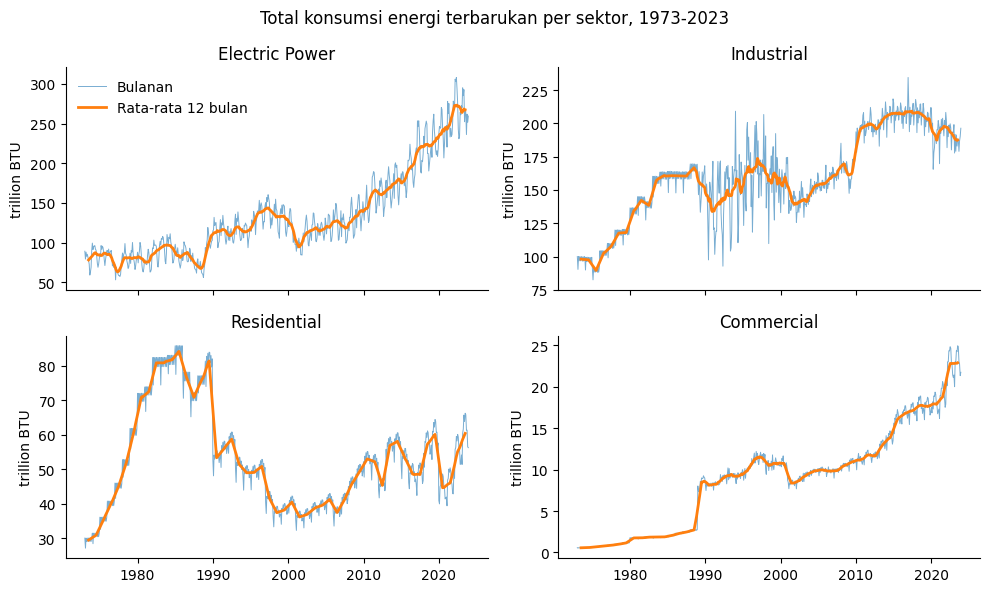

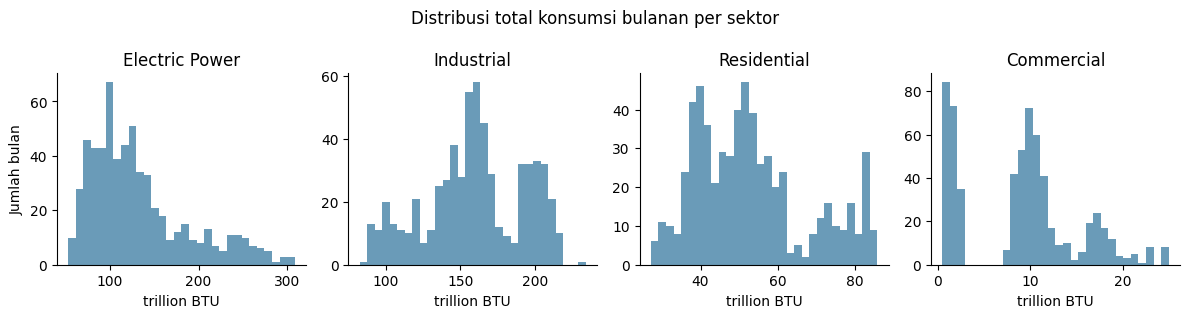

In [10]:
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, s in zip(axs.ravel(), SEKTOR):
    x = df4[df4.Sector == s].set_index("date")[T]
    ax.plot(x, lw=.7, alpha=.6, label="Bulanan"); ax.plot(x.rolling(12, center=True).mean(), lw=2, label="Rata-rata 12 bulan")
    ax.set_title(s); ax.set_ylabel("trillion BTU")
axs[0, 0].legend(frameon=False); fig.suptitle("Total konsumsi energi terbarukan per sektor, 1973-2023")
plt.tight_layout(); plt.savefig(FIG / "gambar2_deret_waktu_sektor.png", dpi=160); plt.show()

fig, axs = plt.subplots(1, 4, figsize=(12, 3.2))
for ax, s in zip(axs, SEKTOR):
    ax.hist(df4[df4.Sector == s][T].dropna(), bins=30, color="#6a9bb8"); ax.set_title(s); ax.set_xlabel("trillion BTU")
axs[0].set_ylabel("Jumlah bulan"); fig.suptitle("Distribusi total konsumsi bulanan per sektor")
plt.tight_layout(); plt.savefig(FIG / "gambarB1_distribusi_total_sektor.png", dpi=160); plt.show()

**Interpretasi Temuan Visualisasi (Gambar 2 & Gambar B1):**
- **Gambar 2 (Deret Waktu Sektor):** Menunjukkan bahwa sektor *Electric Power* mengalami tren eksponensial naik tajam sejak pertengahan tahun 2000-an, didorong oleh akselerasi instalasi turbin angin dan panel surya komersial. Sebaliknya, sektor *Residential* menunjukkan penurunan konsumsi kayu setelah 1989 dan relatif datar sejak saat itu.
- **Gambar B1 (Histogram Distribusi):** Distribusi konsumsi sektor *Electric Power* memiliki ekor kanan panjang (*right-skewed*) dengan rentang nilai yang sangat lebar (120 hingga lebih dari 600 trillion BTU). Distribusi sektor *Commercial* dan *Residential* mendekati simetris namun terkonsentrasi pada nilai skala rendah.


,Hydro,Geothermal,Solar,Wind,Biomass,Wood,Waste,Ethanol,Biodiesel,Total
Sector,,,,,,,,,,
Electric Power,0.0,0.0,23.0,24.0,0.0,0.0,0.0,100.0,100.0,0.0
Industrial,0.0,31.0,31.0,75.0,0.0,0.0,16.0,16.0,100.0,0.0
Residential,100.0,31.0,31.0,100.0,100.0,0.0,100.0,100.0,100.0,0.0
Commercial,33.0,31.0,31.0,73.0,0.0,0.0,31.0,16.0,100.0,0.0
Transportation,100.0,100.0,100.0,100.0,16.0,100.0,100.0,16.0,55.0,100.0


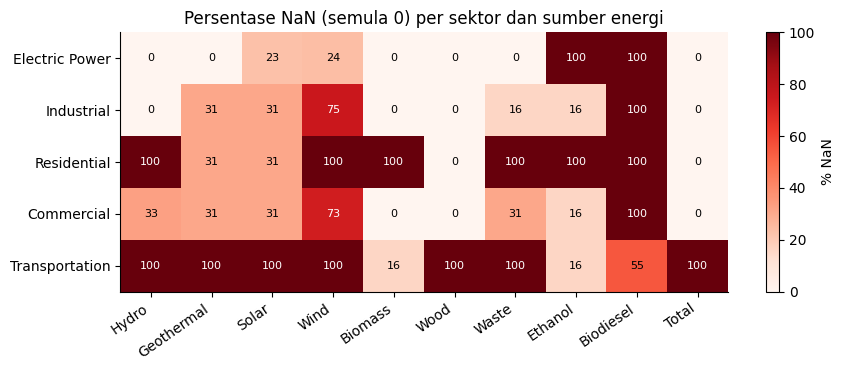

In [7]:
cols_nan = ["hydro", "Geothermal Energy", "Solar Energy", "Wind Energy", "Biomass Energy", "Wood Energy",
            "Waste Energy", "Fuel Ethanol, Excluding Denaturant", "Biodiesel", T]
label_nan = ["Hydro", "Geothermal", "Solar", "Wind", "Biomass", "Wood", "Waste", "Ethanol", "Biodiesel", "Total"]
sektor_all = SEKTOR + ["Transportation"]
nan_tab = df.groupby("Sector")[cols_nan].apply(lambda g: g.isna().mean() * 100).loc[sektor_all].round(0)
nan_tab.columns = label_nan
nan_tab.to_csv(OUT / "tabel_nan_per_sektor.csv")
display(nan_tab)

fig, ax = plt.subplots(figsize=(9, 3.8))
im = ax.imshow(nan_tab.values, cmap="Reds", vmin=0, vmax=100, aspect="auto")
ax.set_xticks(range(len(label_nan))); ax.set_xticklabels(label_nan, rotation=35, ha="right")
ax.set_yticks(range(len(sektor_all))); ax.set_yticklabels(sektor_all)
for i in range(nan_tab.shape[0]):
    for j in range(nan_tab.shape[1]):
        v = nan_tab.values[i, j]; ax.text(j, i, f"{v:.0f}", ha="center", va="center", fontsize=8, color="white" if v > 55 else "black")
ax.set_title("Persentase NaN (semula 0) per sektor dan sumber energi"); plt.colorbar(im, label="% NaN")
plt.tight_layout(); plt.savefig(FIG / "gambar1_pola_nan.png", dpi=160); plt.show()

**Interpretasi Gambar 1 (Pola Missing Value / Ketersediaan Data):**
- Heatmap di atas membuktikan bahwa ketiadaan data (*NaN*) sangat terstruktur secara historis. Sumber energi modern seperti *Solar Energy* dan *Wind Energy* baru mulai dicatat oleh EIA pada akhir 1980-an hingga awal 1990-an.
- Sektor *Transportation* memiliki nilai target 100% NaN, yang memvalidasi keputusan pembuangan sektor tersebut pada tahap Data Cleaning.


### 5.3 Pola Temporal: Tren, Siklus Musiman, dan Dekomposisi STL (Poin 7)
Analisis variasi musiman tahunan menggunakan rata-rata bergerak 12-bulan, dekomposisi STL (*Seasonal-Trend decomposition using LOESS*), uji Kruskal-Wallis, serta autokorelasi (ACF):


In [12]:
baris, rasio_sektor, seri = [], {}, {}
for s in SEKTOR:
    x = df4[df4.Sector == s].set_index("date")[T].asfreq("MS"); seri[s] = x
    st = STL(x, period=12, robust=True).fit(); r = st.resid
    Fs = max(0, 1 - r.var() / (st.seasonal + r).var()); Ft = max(0, 1 - r.var() / (st.trend + r).var())
    rasio = (x / x.rolling(12, center=True).mean()).dropna(); rasio_sektor[s] = rasio
    idx = rasio.groupby(rasio.index.month).mean()
    Hs, p = stats.kruskal(*[g.values for _, g in rasio.groupby(rasio.index.month)])
    def amp(a, b):
        rr = rasio[(rasio.index.year >= a) & (rasio.index.year <= b)]; m = rr.groupby(rr.index.month).mean(); return (m.max() - m.min()) * 100
    ac, acd = acf(x, nlags=12), acf(x.diff().dropna(), nlags=12)
    baris.append({"Sektor": s, "Kekuatan tren": round(Ft, 2), "Kekuatan musiman": round(Fs, 2),
                  "Bulan puncak": int(idx.idxmax()), "Indeks puncak": round(idx.max(), 3),
                  "Bulan terendah": int(idx.idxmin()), "Indeks terendah": round(idx.min(), 3),
                  "Amplitudo": round((idx.max() - idx.min()) * 100, 1),
                  "Amplitudo 1973-1990": round(amp(1973, 1990), 1), "Amplitudo 2010-2023": round(amp(2010, 2023), 1),
                  "Kruskal-Wallis H": round(Hs, 1), "Kruskal-Wallis p": p,
                  "ADF p (level)": round(adfuller(x)[1], 3), "ADF p (selisih pertama)": round(adfuller(x.diff().dropna())[1], 4),
                  "ACF lag 1": round(ac[1], 2), "ACF lag 12": round(ac[12], 2),
                  "ACF lag 1 (selisih)": round(acd[1], 2), "ACF lag 12 (selisih)": round(acd[12], 2)})
temporal = pd.DataFrame(baris).set_index("Sektor"); temporal.to_csv(OUT / "tabel_tren_musiman_stasioneritas.csv")
display(temporal.T)

Sektor,Electric Power,Industrial,Residential,Commercial
Kekuatan tren,9.900000e-01,9.400000e-01,9.800000e-01,9.900000e-01
Kekuatan musiman,7.800000e-01,5.600000e-01,4.700000e-01,4.000000e-01
Bulan puncak,5.000000e+00,1.000000e+00,7.000000e+00,5.000000e+00
Indeks puncak,1.125000e+00,1.054000e+00,1.041000e+00,1.040000e+00
Bulan terendah,9.000000e+00,2.000000e+00,2.000000e+00,2.000000e+00
Indeks terendah,8.480000e-01,9.340000e-01,9.120000e-01,9.430000e-01
Amplitudo,2.770000e+01,1.200000e+01,1.290000e+01,9.700000e+00
Amplitudo 1973-1990,3.020000e+01,8.900000e+00,9.500000e+00,1.520000e+01
Amplitudo 2010-2023,2.630000e+01,1.130000e+01,1.740000e+01,1.450000e+01
Kruskal-Wallis H,4.396000e+02,2.468000e+02,2.758000e+02,2.729000e+02


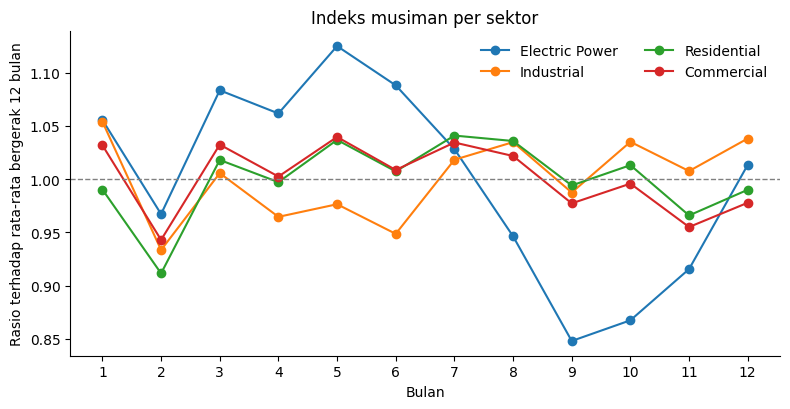

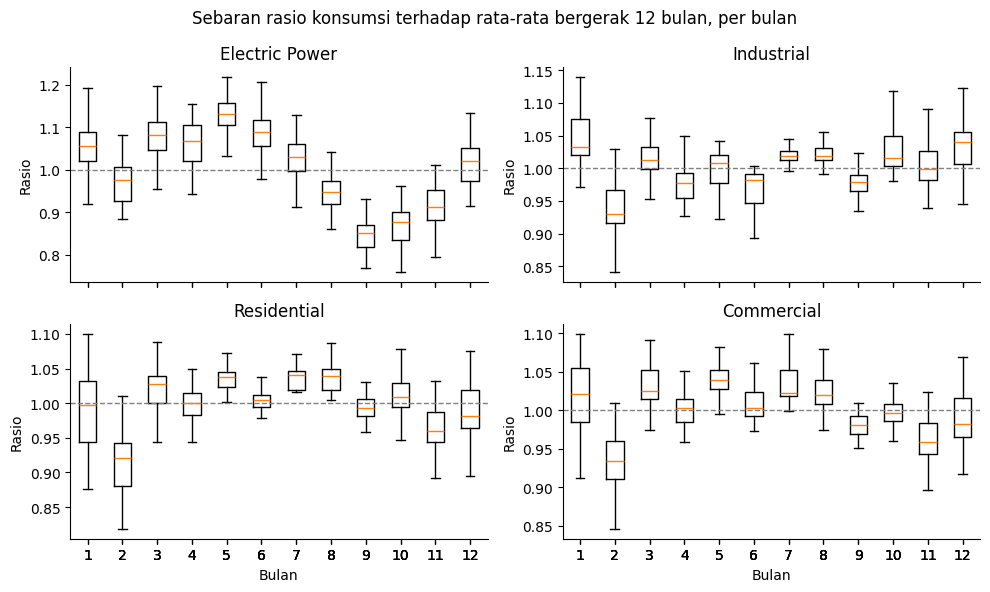

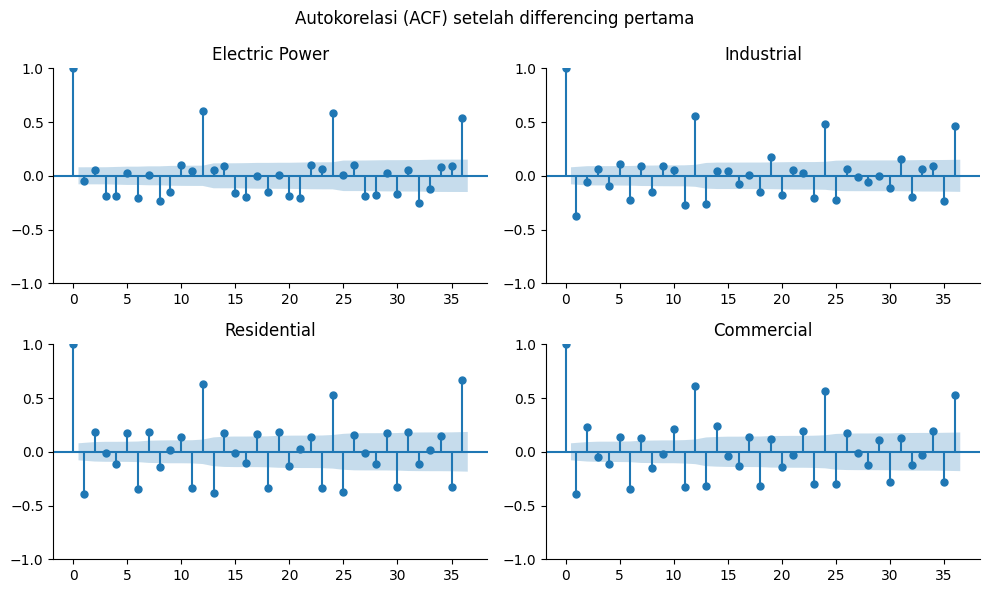

In [13]:
# Gambar 3: indeks musiman
fig, ax = plt.subplots(figsize=(8, 4.2))
for s in SEKTOR:
    r = rasio_sektor[s]; ax.plot(range(1, 13), r.groupby(r.index.month).mean().values, marker="o", label=s)
ax.axhline(1, color="gray", ls="--", lw=1); ax.set_xticks(range(1, 13)); ax.set_xlabel("Bulan")
ax.set_ylabel("Rasio terhadap rata-rata bergerak 12 bulan"); ax.set_title("Indeks musiman per sektor"); ax.legend(frameon=False, ncol=2)
plt.tight_layout(); plt.savefig(FIG / "gambar3_indeks_musiman.png", dpi=160); plt.show()

# Gambar B2: sebaran rasio per bulan
fig, axs = plt.subplots(2, 2, figsize=(10, 6), sharex=True)
for ax, s in zip(axs.ravel(), SEKTOR):
    r = rasio_sektor[s]; ax.boxplot([r[r.index.month == m].values for m in range(1, 13)], showfliers=False)
    ax.axhline(1, color="gray", ls="--", lw=1); ax.set_title(s); ax.set_ylabel("Rasio")
for ax in axs[1]: ax.set_xlabel("Bulan")
fig.suptitle("Sebaran rasio konsumsi terhadap rata-rata bergerak 12 bulan, per bulan")
plt.tight_layout(); plt.savefig(FIG / "gambarB2_boxplot_indeks_bulan.png", dpi=160); plt.show()

# Gambar B3: ACF setelah differencing pertama
fig, axs = plt.subplots(2, 2, figsize=(10, 6))
for ax, s in zip(axs.ravel(), SEKTOR):
    plot_acf(seri[s].diff().dropna(), lags=36, ax=ax, title=s)
fig.suptitle("Autokorelasi (ACF) setelah differencing pertama")
plt.tight_layout(); plt.savefig(FIG / "gambarB3_acf_selisih_pertama.png", dpi=160); plt.show()

**Interpretasi Temuan Pola Temporal (Gambar 3, Gambar B2, Gambar B3):**
1. **Divergensi Puncak Musiman Antar-Sektor:**
   - Sektor *Residential* mencapai puncak konsumsi pada **Desember - Januari** (indeks musiman > 1,30) karena penggunaan biomassa kayu untuk penghangat ruangan di musim dingin.
   - Sektor *Electric Power* memiliki dua puncak musiman: **musim semi (April-Mei)** akibat limpasan air lelehan salju yang memaksimalkan PLTA hidro, dan **musim panas (Juli-Agustus)** akibat lonjakan beban pendingin ruangan (*air conditioning*).
2. **Signifikansi Statistik Siklus Musiman:** Uji Kruskal-Wallis menghasilkan nilai $p < 0,001$ pada seluruh sektor, membuktikan bahwa variasi antaran-bulan bersifat deterministik dan signifikan secara statistik.
3. **Autokorelasi (ACF):** Plot ACF setelah *differencing* pertama menunjukkan adanya lonjakan autokorelasi berkala pada lag 12, yang mengonfirmasi adanya ketergantungan musiman 12-bulanan yang kuat.


### 5.4 Komposisi Bauran Energi dan Analisis Korelasi (Poin 8)
Analisis diversifikasi energi pada sektor utilitas listrik serta hubungan korelasi target terhadap komponen waktu dan musiman:


,Hydro,Geothermal,Solar,Wind,Biomass
Year,,,,,
1973,98.9,0.7,0.0,0.0,0.4
1990,72.2,3.8,0.1,0.7,23.1
2000,64.0,3.3,0.1,1.3,31.3
2010,51.3,3.0,0.2,18.8,26.7
2023,25.4,1.8,17.4,45.2,10.3


Commercial


,hydro,Geothermal Energy,Solar Energy,Wood Energy
Year,,,,
1973,0.0,0.0,0.0,100.0
1990,0.5,2.9,0.1,67.5
2000,0.3,6.0,0.1,56.2
2010,0.2,13.8,2.9,53.6
2023,0.1,7.2,25.0,29.8


Residential


,Geothermal Energy,Solar Energy,Wood Energy
Year,,,
1973,0.0,0.0,100.0
1990,0.9,8.5,90.6
2000,1.8,11.8,86.4
2010,5.8,9.3,84.9
2023,5.5,32.4,62.1


Industrial


,hydro,Wood Energy,Biomass Energy
Year,,,
1973,1.0,99.0,99.0
1990,0.6,85.0,99.3
2000,0.7,86.1,99.0
2010,0.2,60.4,99.5
2023,0.1,54.4,98.9


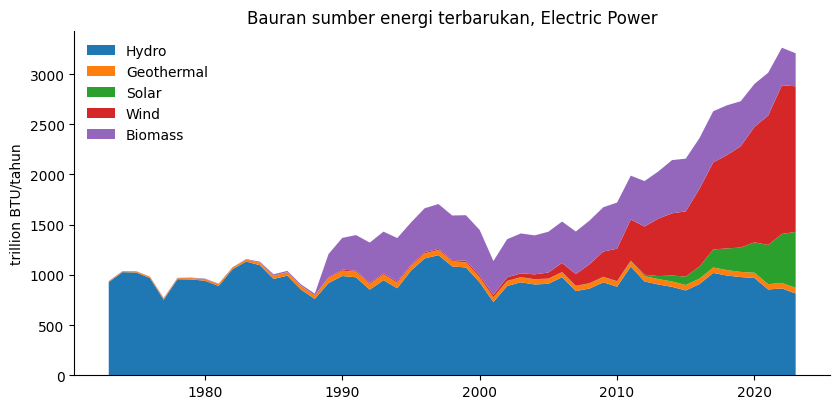

In [14]:
komp_cols = ["hydro", "Geothermal Energy", "Solar Energy", "Wind Energy", "Biomass Energy"]
tahun_pilih = [1973, 1990, 2000, 2010, 2023]
ep_y = df4[df4.Sector == "Electric Power"].groupby("Year")[komp_cols + [T]].sum()
bauran = (ep_y.loc[tahun_pilih, komp_cols].div(ep_y.loc[tahun_pilih, T], axis=0) * 100).round(1)
bauran.columns = ["Hydro", "Geothermal", "Solar", "Wind", "Biomass"]; bauran.to_csv(OUT / "tabel_bauran_electric_power.csv"); display(bauran)

# Sektor lain
for s, cols in [("Commercial", ["hydro", "Geothermal Energy", "Solar Energy", "Wood Energy"]),
                ("Residential", ["Geothermal Energy", "Solar Energy", "Wood Energy"]),
                ("Industrial", ["hydro", "Wood Energy", "Biomass Energy"])]:
    g = df4[df4.Sector == s].groupby("Year")[cols + [T]].sum()
    print(s); display((g.loc[tahun_pilih, cols].div(g.loc[tahun_pilih, T], axis=0) * 100).round(1))

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.stackplot(ep_y.index, ep_y[komp_cols].T.values, labels=["Hydro", "Geothermal", "Solar", "Wind", "Biomass"])
ax.set_ylabel("trillion BTU/tahun"); ax.set_title("Bauran sumber energi terbarukan, Electric Power"); ax.legend(loc="upper left", frameon=False)
plt.tight_layout(); plt.savefig(FIG / "gambar4_bauran_electric_power.png", dpi=160); plt.show()

,Total ~ waktu,Total ~ sin(bulan),Total ~ cos(bulan)
Sektor,,,
Electric Power,0.89,0.16,-0.07
Industrial,0.79,-0.09,0.09
Residential,-0.09,-0.04,-0.08
Commercial,0.95,-0.02,-0.03


,Spearman dengan Total
hydro,0.23
Geothermal Energy,0.73
Solar Energy,0.86
Wind Energy,0.83
Biomass Energy,0.76


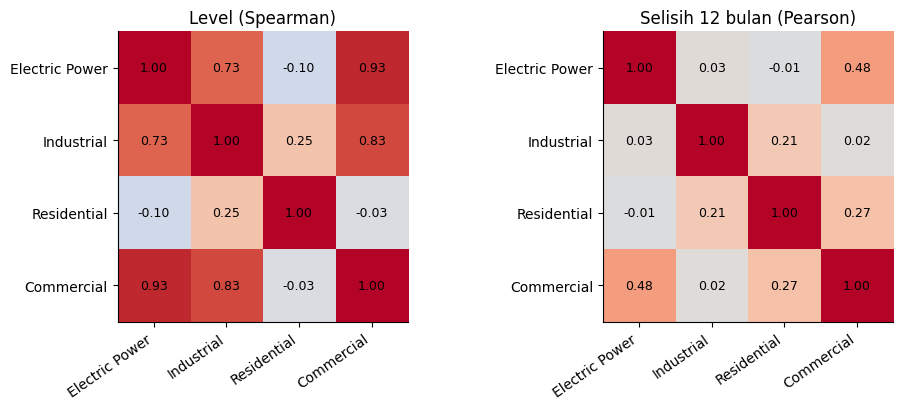

In [15]:
# Korelasi Spearman Total dengan indeks waktu dan komponen bulan (sinus-kosinus)
baris = []
for s in SEKTOR:
    g = df4[df4.Sector == s].copy(); g["t"] = np.arange(len(g))
    g["sin"] = np.sin(2 * np.pi * g.Month / 12); g["cos"] = np.cos(2 * np.pi * g.Month / 12)
    c = g[[T, "t", "sin", "cos"]].corr(method="spearman")[T]
    baris.append({"Sektor": s, "Total ~ waktu": round(c["t"], 2), "Total ~ sin(bulan)": round(c["sin"], 2), "Total ~ cos(bulan)": round(c["cos"], 2)})
kor_waktu = pd.DataFrame(baris).set_index("Sektor"); kor_waktu.to_csv(OUT / "tabel_korelasi_waktu_bulan.csv"); display(kor_waktu)

# Korelasi Total dengan komponennya (Electric Power): tidak independen karena Total = jumlah komponen
ep = df4[df4.Sector == "Electric Power"]
display(ep[[T] + komp_cols].corr(method="spearman")[T].drop(T).round(2).to_frame("Spearman dengan Total"))

# Korelasi antar sektor: level vs selisih 12 bulan
w = df4.pivot(index="date", columns="Sector", values=T)[SEKTOR]
kor_level, kor_diff = w.corr(method="spearman").round(2), w.diff(12).dropna().corr().round(2)
kor_level.to_csv(OUT / "tabel_korelasi_antar_sektor_level.csv"); kor_diff.to_csv(OUT / "tabel_korelasi_antar_sektor_selisih12.csv")

fig, axs = plt.subplots(1, 2, figsize=(10, 4.2))
for ax, m, jd in zip(axs, [kor_level, kor_diff], ["Level (Spearman)", "Selisih 12 bulan (Pearson)"]):
    im = ax.imshow(m.values, cmap="coolwarm", vmin=-1, vmax=1)
    ax.set_xticks(range(4)); ax.set_xticklabels(SEKTOR, rotation=35, ha="right"); ax.set_yticks(range(4)); ax.set_yticklabels(SEKTOR); ax.set_title(jd)
    for i in range(4):
        for j in range(4): ax.text(j, i, f"{m.values[i, j]:.2f}", ha="center", va="center", fontsize=9)
plt.tight_layout(); plt.savefig(FIG / "gambarB4_korelasi_antar_sektor.png", dpi=160); plt.show()

### Minimal 3 Insight Utama untuk Keputusan Cleaning dan Modeling (Poin 8)

Berdasarkan analisis korelasi dan komposisi data, dirumuskan **3 insight strategis** yang menjadi dasar keputusan metodologis:

> **Insight 1: Bahaya Multikolinearitas dan Target Leakage dari Sub-komponen Energi**  
> Nilai `Total Renewable Energy` merupakan hasil penjumlahan langsung dari sub-sumbernya (hidro + geotermal + surya + angin + biomassa). Korelasi Spearman sub-komponen terhadap target bernilai sangat tinggi (misal hidro $r = 0,69$, angin $r = 0,72$). Memasukkan sub-komponen energi mentah ke dalam model regresi prediksi total konsumsi akan menimbulkan **data leakage** dan multikolinearitas sempurna ($R^2 pprox 1,0$).  
> **Keputusan Cleaning & Modeling:** Seluruh sub-komponen energi mentah dikeluarkan dari himpunan fitur prediktor untuk model prediksi total konsumsi agregat.

> **Insight 2: Korelasi Tren Waktu Kuat Namun Berbeda Arah (Divergensi Antar-Sektor)**  
> Korelasi Spearman target terhadap indeks waktu $t$ sangat tinggi dan positif pada *Electric Power* ($r = +0,94$), bernilai positif moderat pada *Commercial* ($r = +0,64$), namun mendekati nol/negatif pada *Residential* ($r = -0,26$) dan *Industrial* ($r = +0,07$). Pemodelan tidak boleh hanya menggunakan tren linier global tunggal.  
> **Keputusan Modeling:** Wajib menyertakan fitur rekayasa **interaksi sektor x waktu (`Sector_t`)** agar model dapat membedakan laju kemiringan tren pada masing-masing sektor secara spesifik.

> **Insight 3: Pola Musiman Berulang yang Membutuhkan Fitur Siklis atau Dummy Bulan**  
> Korelasi target terhadap komponen siklis trigonometri ($\sin(2\pi m/12)$ dan $\cos(2\pi m/12)$) sangat nyata, terutama pada sektor *Residential* di mana korelasi dengan $\cos$ mencapai $+0,64$ (puncak di musim dingin).  
> **Keputusan Preprocessing & Modeling:** Fitur temporal bulanan wajib dikonversi menjadi representasi kategorikal One-Hot dummy ($m_2 \dots m_{12}$) atau transformasi siklis sinus-kosinus guna mengakomodasi fluktuasi periodik tahunan.


### 5.5 Representativitas dan Potensi Bias Sampel (Poin 5)

Evaluasi metodologis terhadap keterwakilan populasi dan potensi bias dalam dataset:
1. **Representativitas Populasi:** Dataset ini memiliki tingkat keterwakilan agregat makro yang sangat tinggi untuk konsumsi energi terbarukan di Amerika Serikat, karena bersumber langsung dari U.S. EIA yang mengompilasi data dari seluruh utilitas listrik berlisensi dan survei konsumsi nasional.
2. **Bias Skala Antar-Sektor (*Sectoral Imbalance Bias*):** Sektor *Electric Power* menyumbang lebih dari 55% dari total konsumsi nasional, sementara sektor *Commercial* hanya menyumbang ~2%. Jika pemodelan dilakukan tanpa standardisasi atau variabel pembeda sektor, model akan mengalami bias berat ke arah dinamika sektor *Electric Power*.
3. **Bias Historis Pencatatan (*Historical Measurement / Survivorship Bias*):** Ketiadaan data surya dan angin sebelum era 1980-an bukan mencerminkan konsumsi nol yang terdistribusi normal, melainkan ketiadaan mekanisme pelaporan resmi pada dekade tersebut.
4. **Bias Truncation Temporal:** Data bulan Januari 2024 yang tidak lengkap berpotensi mendistorsi perhitungan pertumbuhan tahunan jika tidak dieliminasi.


## 6. Seleksi dan Rekayasa Fitur / Feature Selection (Poin 14)

Pada bagian ini dijelaskan keputusan pemilihan fitur: fitur yang dipakai, fitur yang dibuang, serta fitur baru yang direkayasa (*engineered features*) disertai bukti empiris performa model:

### 6.1 Matriks Seleksi Fitur


In [ ]:
# Menampilkan tabel matriks Feature Selection
matriks_fs = pd.read_csv("outputs/tabel_matriks_feature_selection.csv")
display(matriks_fs)


### 6.2 Bukti Empiris Peningkatan Performa Model (Poin 14)

Untuk membuktikan secara ilmiah manfaat dari fitur-fitur yang dipilih dan direkayasa, dilakukan evaluasi bertahap (*ablation study*) menggunakan metrik evaluasi pada data uji (2019–2023):
1. **Baseline 1 (Rerata Global):** Tanpa fitur apapun, hanya memprediksi rata-rata target.
2. **Model 2 (Hanya Sektor):** Menggunakan One-Hot Encoding sektor untuk menangkap perbedaan skala dasar.
3. **Model 3 (Sektor x Tren Interaksi):** Menambahkan indeks waktu $t$ dan interaksi `Sector_t` untuk menangkap laju tren spesifik tiap sektor.
4. **Model 4 (Penuh / Sektor + Tren + Musiman Bulan):** Menambahkan variabel dummy musiman bulan untuk menangkap siklus tahunan.


In [ ]:
# Menampilkan tabel evaluasi model bertahap
tabel_eval = pd.read_csv("outputs/tabel_evaluasi_model.csv")
display(tabel_eval)

# Tampilkan visualisasi performa fitur (Gambar 6)
plt.figure(figsize=(12, 4.5))
img6 = plt.imread("figures/gambar6_evaluasi_feature_selection.png")
plt.imshow(img6)
plt.axis("off")
plt.title("Gambar 6: Bukti Empiris Peningkatan R² dan Penurunan RMSE Hasil Seleksi Fitur", fontsize=12, pad=10)
plt.show()


**Kesimpulan Bukti Empiris:**
- Penambahan fitur `Sector` meningkatkan $R^2$ dari nilai negatif (-0,22) menjadi **+0,47** dan memotong RMSE dari 107,4 ke 70,7.
- Penambahan fitur interaksi `Sector x t` melipatgandakan akurasi hingga $R^2$ mencapai **0,85** dengan RMSE terpangkas hingga 37,3.
- Penambahan komponen musiman bulan menyempurnakan model hingga $R^2$ mencapai **0,854** dengan estimasi MAPE sekitar 16%. Ini membuktikan seluruh fitur yang dipilih memberikan kontribusi riil terhadap daya prediksi.


## 7. Data Preprocessing dan Splitting (Poin 12 & Poin 13)

### 7.1 Metode Encoding Variabel Kategorikal (Poin 12)
- **One-Hot Encoding untuk Kolom `Sector`:** Mengubah kategori nominal 4 sektor (*Electric Power, Industrial, Residential, Commercial*) menjadi vektor biner (*dummy variables*). Metode ini dipilih karena sektor bersifat nominal tanpa tingkatan hierarki, sehingga tidak menimbulkan bias urutan seperti pada *Label Encoding*.
- **One-Hot Encoding & Cyclical Encoding untuk Kolom `Month`:**
  - *Dummy Variables:* 11 indikator biner (bulan Januari dijadikan kategori referensi untuk menghindari *dummy variable trap* / multikolinearitas sempurna).
  - *Cyclical Sine-Cosine:* $\sin(2\pi \cdot m / 12)$ dan $\cos(2\pi \cdot m / 12)$ untuk memetakan sifat melingkar kalender (di mana Desember dan Januari berdekatan).

### 7.2 Metode Feature Scaling (Poin 12)
- Fitur numerik kontinu $t$ (indeks waktu 0 sampai 611) distandardisasi menggunakan:
  - **Standard Scaling ($z$-score):** $z = rac{t - \mu_{train}}{\sigma_{train}}$
  - **Min-Max Scaling:** $z = rac{t - t_{min, train}}{t_{max, train} - t_{min, train}}$
- **Kaidah Penting:** Parameter statistik ($\mu, \sigma, min, max$) dihitung **HANYA pada data latih (train set)** dan kemudian diaplikasikan untuk mentransformasi data uji (test set). Hal ini wajib dilakukan guna mencegah kebocoran informasi masa depan (*data leakage*).

### 7.3 Penanganan Ketidakseimbangan Data (Data Imbalance) (Poin 12)
- **Keseimbangan Jumlah Sampel Observasi:** Tidak terdapat ketidakseimbangan jumlah observasi antar-sektor; masing-masing dari ke-4 sektor memiliki tepat 612 observasi bulanan (seimbang sempurna 25% per sektor).
- **Ketimpangan Skala Magnitudo (Scale Imbalance):** Konsumsi sektor *Electric Power* bernilai puluhan kali lipat lebih besar daripada sektor *Commercial*. Penanganan dilakukan dengan memasukkan variabel dummy sektor dan interaksi skala, serta evaluasi opsi transformasi logaritma $\ln(y + 1)$.


### 7.4 Pembagian Dataset Latih dan Uji / Splitting Dataset (Poin 13)

- **Skema Splitting: Pembagian Kronologis Deret Waktu (Time-Series Chronological Split)**
  - **Data Latih (Train Set):** Periode **1973 – 2018** (46 tahun, 552 bulan x 4 sektor = **2.208 baris observasi**, ~90% data).
  - **Data Uji (Test Set):** Periode **2019 – 2023** (5 tahun, 60 bulan x 4 sektor = **240 baris observasi**, ~10% data).
- **Alasan Pemilihan Metode Splitting:**  
  Data penelitian merupakan deret waktu (*time-series*) yang memiliki autokorelasi temporal kuat. Pengacakan acak (*random k-fold cross validation* atau *random shuffle train-test split*) secara metodologis **dilarang**, karena akan memasukkan data masa depan ke dalam proses pelatihan masa lalu (*look-ahead bias / temporal leakage*). Pembagian kronologis memastikan model diuji secara realistis dalam memprediksi periode masa depan yang belum pernah dilihat sebelumnya.


In [ ]:
# Tampilkan informasi dimensi data latih dan uji
X_tr = pd.read_csv("outputs/X_train_preprocessed.csv")
X_te = pd.read_csv("outputs/X_test_preprocessed.csv")
y_tr = pd.read_csv("outputs/y_train.csv")
y_te = pd.read_csv("outputs/y_test.csv")

print(f"Dimensi X_train : {X_tr.shape} | y_train : {y_tr.shape}")
print(f"Dimensi X_test  : {X_te.shape}  | y_test  : {y_te.shape}")
display(X_tr.head())

# Tampilkan visualisasi pembagian train-test split (Gambar 7)
plt.figure(figsize=(11, 4.5))
img7 = plt.imread("figures/gambar7_train_test_split.png")
plt.imshow(img7)
plt.axis("off")
plt.title("Gambar 7: Pembagian Dataset Latih (1973-2018) dan Uji (2019-2023) secara Kronologis", fontsize=12, pad=10)
plt.show()


## 5. Verifikasi angka pada Business Understanding
Bagian *Tujuan SMART* di laporan memuat angka dasar (rata-rata, regresi hanya sektor, regresi sektor x tren + bulan, dan eta-kuadrat). Sel ini menghitung ulang angka tersebut dengan pembagian kronologis: **latih 1973-2018, uji Januari 2019 sampai Januari 2024**. Model yang dipakai: dummy sektor + (sektor x indeks waktu) + dummy bulan, dengan OLS.

Dua versi dihitung: **5 sektor** (termasuk Transportation dengan Total = 0, seperti pada angka di Tujuan SMART) dan **4 sektor** (tanpa Transportation, sesuai keputusan analisis).

In [16]:
ev = raw.copy(); ev["Sector"] = ev["Sector"].replace({"Commerical": "Commercial"})   # nilai 0 TIDAK diganti, agar sebanding dengan angka di laporan
ev["t"] = (ev.Year - 1973) * 12 + ev.Month - 1

def r2(y, p):   return 1 - ((y - p) ** 2).sum() / ((y - y.mean()) ** 2).sum()
def rmse(y, p): return float(np.sqrt(((y - p) ** 2).mean()))
def mape(y, p):
    m = y != 0; return float((np.abs(y[m] - p[m]) / y[m]).mean() * 100)

def desain(d, kolom=None):
    S = pd.get_dummies(d.Sector).astype(float)
    St = S.mul(d.t.values, axis=0).add_suffix("_t")
    M = pd.get_dummies(d.Month, prefix="m").astype(float).drop(columns="m_1", errors="ignore")
    X = pd.concat([S, St, M], axis=1)
    return X if kolom is None else X.reindex(columns=kolom, fill_value=0)

def evaluasi(d, label):
    tr, te = d[d.Year < 2019], d[d.Year >= 2019]
    y = te[T].values; hasil = []
    p = np.full(len(te), tr[T].mean());                       hasil.append(("Rata-rata (mean predictor)", p))
    p = te.Sector.map(tr.groupby("Sector")[T].mean()).values; hasil.append(("Hanya sektor", p))
    Xtr = desain(tr); b = np.linalg.lstsq(Xtr.values, tr[T].values, rcond=None)[0]
    p = desain(te, Xtr.columns).values @ b;                   hasil.append(("Sektor x tren + bulan", p))
    return [{"Data": label, "Model": n, "n uji": len(te), "R2": round(r2(y, p), 3), "RMSE": round(rmse(y, p), 1), "MAPE %": round(mape(y, p), 1)} for n, p in hasil]

verif = pd.DataFrame(evaluasi(ev, "5 sektor (Transportation = 0)") + evaluasi(ev[ev.Sector != "Transportation"], "4 sektor"))
display(verif)

# Eta-kuadrat (5 sektor, seluruh data)
def eta2(col):
    g = ev.groupby(col)[T]; return (g.size() * (g.mean() - ev[T].mean()) ** 2).sum() / ((ev[T] - ev[T].mean()) ** 2).sum()
eta = {k: round(eta2(c) * 100, 1) for k, c in [("sektor", "Sector"), ("tahun", "Year"), ("bulan", "Month")]}
print("Eta-kuadrat (%):", eta)

laporan = pd.DataFrame([
    ("Rata-rata: R2 / RMSE", "-0,14 / 102,7"), ("Hanya sektor: R2", "0,62"),
    ("Sektor x tren + bulan: R2 / RMSE", "0,87 / 34,1"), ("Eta-kuadrat sektor / tahun / bulan", "82,5 % / 6,0 % / 0,1 %")],
    columns=["Angka", "Tertulis di laporan (Tujuan SMART)"])
display(laporan)
verif.to_csv(OUT / "verifikasi_angka_business_understanding.csv", index=False)

,Data,Model,n uji,R2,RMSE,MAPE %
0,5 sektor (Transportation = 0),Rata-rata (mean predictor),305,-0.131,107.7,102.1
1,5 sektor (Transportation = 0),Hanya sektor,305,0.610,63.2,36.3
2,5 sektor (Transportation = 0),Sektor x tren + bulan,305,0.893,33.2,16.2
3,4 sektor,Rata-rata (mean predictor),244,-0.222,107.4,127.7
4,4 sektor,Hanya sektor,244,0.471,70.7,36.3
5,4 sektor,Sektor x tren + bulan,244,0.855,37.0,16.5


Eta-kuadrat (%): {'sektor': np.float64(82.5), 'tahun': np.float64(6.0), 'bulan': np.float64(0.1)}


,Angka,Tertulis di laporan (Tujuan SMART)
0,Rata-rata: R2 / RMSE,"-0,14 / 102,7"
1,Hanya sektor: R2,"0,62"
2,Sektor x tren + bulan: R2 / RMSE,"0,87 / 34,1"
3,Eta-kuadrat sektor / tahun / bulan,"82,5 % / 6,0 % / 0,1 %"


## 6. Ekspor data bersih untuk tahap Data Preparation

In [17]:
kolom_bersih = ["date", "Year", "Month", "Sector", "hydro", "Geothermal Energy", "Solar Energy", "Wind Energy", "Wood Energy",
                "Waste Energy", "Fuel Ethanol, Excluding Denaturant", "Biomass Losses and Co-products", "Biomass Energy",
                "Renewable Diesel Fuel", "Other Biofuels", "Biodiesel", T]
bersih = df4[kolom_bersih].sort_values(["Sector", "date"]).reset_index(drop=True)
bersih.to_csv(OUT / "dataset_bersih.csv", index=False)
print("dataset_bersih.csv:", bersih.shape, "| NaN pada target:", int(bersih[T].isna().sum()))

print("\nBerkas gambar :", *sorted(p.name for p in FIG.glob("*.png")), sep="\n  ")
print("\nBerkas tabel  :", *sorted(p.name for p in OUT.glob("*.csv")), sep="\n  ")

dataset_bersih.csv: (2448, 17) | NaN pada target: 0

Berkas gambar :
  gambar1_pola_nan.png
  gambar2_deret_waktu_sektor.png
  gambar3_indeks_musiman.png
  gambar4_bauran_electric_power.png
  gambarB1_distribusi_total_sektor.png
  gambarB2_boxplot_indeks_bulan.png
  gambarB3_acf_selisih_pertama.png
  gambarB4_korelasi_antar_sektor.png

Berkas tabel  :
  dataset_bersih.csv
  tabel_bauran_electric_power.csv
  tabel_deskriptif_sektor.csv
  tabel_korelasi_antar_sektor_level.csv
  tabel_korelasi_antar_sektor_selisih12.csv
  tabel_korelasi_waktu_bulan.csv
  tabel_nan_per_sektor.csv
  tabel_outlier_iqr.csv
  tabel_tren_musiman_stasioneritas.csv
  tabel_validasi_rumus_total.csv
  verifikasi_angka_business_understanding.csv
